# 06b · Challenger para periodos de evento: reinicio de régimen y target multiplicativo
**El 06 sigue siendo la versión oficial.** Este notebook no modifica `06_modelado.ipynb`, ni `src/`, ni `outputs/`: todo se calcula en memoria. Un modelo de aquí solo sustituiría al del 06 si cumple los criterios de la sección 0.

Tiene tres partes:
1. **Backtest continuo.** Se añaden folds *extra* que cubren los huecos de `FOLDS` (abr–may, jun–sep y las semanas pegadas a Buen Fin y Navidad), para predecir de punta a punta desde 2023-03-27 hasta 2024-02-25. Los 8 folds oficiales no cambian.
2. **Idea 1, reinicio de régimen.** Evita que, al terminar un evento, los rezagos de 14–35 días sigan arrastrando el pico (histéresis).
3. **Idea 2, estructura multiplicativa.** El modelo aprende el *multiplicador* sobre el baseline y no el nivel, así los árboles no necesitan reproducir niveles que nunca vieron.
4. **Ampliación (sección 6).** Sensibilidad de las ventanas de evento y variante V1b con fin de régimen el 31-dic.

## 0. Protocolo y criterios de sustitución (fijados antes de ejecutar las variantes)

**Qué se vio antes de definir las ideas.** El diagnóstico (histéresis tras Navidad, rampa navideña corta) salió de mirar las predicciones de REF en los folds de evento. Por eso esos folds **no son una validación independiente** de las ideas: la evidencia a favor de la idea 1 es el mecanismo, más que no cambie nada fuera de las ventanas de evento.

**Roles de los folds.** Los 8 oficiales conservan su rol del 06 (desarrollo, confirmación, evento, post-evento). Los folds extra se **reportan y no se usan para seleccionar nada**.

**Variantes**
- `REF`: el modelo del 06 (30 features, objetivo L2 en log, hiperparámetros de referencia).
- `V1 reinicio`: REF x factor de reinicio (sección 3).
- `V2 multiplicativo`: LightGBM con objetivo `log(y / base_sma4)`, pronóstico = `base_sma4 x exp(f)` (sección 4).
- `V1+V2`: ambas.

**Criterios para que un challenger sustituya a REF** (las tres):
- **C1, sin regresión en regulares:** el WAPE medio de los folds regulares (oficiales y extra) no es más de 0.2 pts peor que REF. Es la regla del 06 usada en sentido inverso.
- **C2, post-evento:** el sesgo de cadena en `post_navidad_2024` queda entre −15 % y +15 % (REF: +57 %).
- **C3, eventos:** el WAPE de `buen_fin_2023` y `navidad_2023` no es más de 1 pt peor que REF. Cada evento ocurre una sola vez, así que se reportan y no se optimiza contra ellos.

Con una sola ocurrencia de cada evento, cumplir los criterios **no demuestra** que el challenger generalice a 2024; solo muestra que no rompe lo que ya funcionaba y que corrige un defecto mecánico.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
%config InlineBackend.figure_format = 'retina'

from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
from src.features.engineering import FeatureConfig, build_features
from src.models.backtest import FOLDS, Fold, add_week
from src.models.significance import compare
from src.models import train as T
plt.rcParams.update({'figure.figsize': (11, 3.8), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 170, 'display.max_columns', 30, 'display.float_format', '{:,.2f}'.format)

KEY = ['store_id', 'category', 'date']
p = build_panel(load_transactions(), load_stores(), load_calendar())
cfg = FeatureConfig(horizon=14); cols = cfg.feature_columns(); P0 = dict(T.DEFAULT_PARAMS); F = build_features(p, cfg)
print(len(cols), 'features |', int(F.eligible.sum()), 'filas elegibles | datos:', F.date.min().date(), '→', F.date.max().date())

30 features | 190998 filas elegibles | datos: 2023-01-01 → 2024-02-29


## 1. Backtest continuo: cubrir los huecos de `FOLDS`

`FOLDS` (en `src/models/backtest.py`) tiene ocho ventanas de prueba y entre ellas quedan huecos, por eso en la gráfica del 06 no hay predicciones de julio ni de agosto. No es falta de datos: el panel tiene ventas todas esas semanas. Los huecos son:

| Hueco | Semanas | Comentario |
|---|---|---|
| 2023-04-24 → 05-28 | 5 | regular |
| 2023-06-26 → 09-03 | 10 | regular (julio y agosto) |
| 2023-10-30 → 11-05 | 1 | **pre-rampa del Buen Fin** (la venta ya sube ~30 %) |
| 2023-12-04 → 12-10 | 1 | rampa navideña |

Se añaden folds extra contiguos a los oficiales, con la misma mecánica: reentrenar con fechas ≤ inicio − 14 y pronosticar la ventana completa.
Antes de abril de 2023 no se puede predecir: el primer fold oficial ya entrena con apenas ~4 semanas de historia elegible, porque los rezagos llegan a 35 días.

In [2]:
OFFICIAL = [f.name for f in FOLDS]
EXTRA = [Fold('abr_may_2023', 'regular', '2023-04-24', '2023-05-28'),
         Fold('jun_jul_2023', 'regular', '2023-06-26', '2023-07-23'),
         Fold('jul_ago_2023', 'regular', '2023-07-24', '2023-08-20'),
         Fold('ago_sep_2023', 'regular', '2023-08-21', '2023-09-03'),
         Fold('pre_buen_fin_2023', 'evento', '2023-10-30', '2023-11-05'),
         Fold('pre_navidad_2023', 'evento', '2023-12-04', '2023-12-10')]
ALL = sorted(FOLDS + EXTRA, key=lambda f: f.start)
for a, b in zip(ALL, ALL[1:]):
    assert pd.Timestamp(b.start) == pd.Timestamp(a.end) + pd.Timedelta(days=1), (a.name, b.name)   # cobertura contigua
cov = pd.DataFrame([{'fold': f.name, 'tipo': f.kind, 'inicio': f.start, 'fin': f.end,
                     'semanas': ((pd.Timestamp(f.end) - pd.Timestamp(f.start)).days + 1) // 7,
                     'origen': 'oficial (06)' if f.name in OFFICIAL else 'extra (06b)'} for f in ALL]).set_index('fold')
print('Cobertura contigua', ALL[0].start, '→', ALL[-1].end, '|', int(cov.semanas.sum()), 'semanas')
cov

Cobertura contigua 2023-03-27 → 2024-02-25 | 48 semanas


,tipo,inicio,fin,semanas,origen
fold,,,,,
semana_santa_2023,regular,2023-03-27,2023-04-23,4,oficial (06)
abr_may_2023,regular,2023-04-24,2023-05-28,5,extra (06b)
may_jun_2023,regular,2023-05-29,2023-06-25,4,oficial (06)
jun_jul_2023,regular,2023-06-26,2023-07-23,4,extra (06b)
jul_ago_2023,regular,2023-07-24,2023-08-20,4,extra (06b)
ago_sep_2023,regular,2023-08-21,2023-09-03,2,extra (06b)
sep_2023,regular,2023-09-04,2023-10-01,4,oficial (06)
oct_2023,regular,2023-10-02,2023-10-29,4,oficial (06)
pre_buen_fin_2023,evento,2023-10-30,2023-11-05,1,extra (06b)


In [3]:
ref = T.run_backtest(F, cfg, P0, cols, ALL).rename(columns={'pred': 'pred_ref'})
# Los folds oficiales deben reproducir exactamente el backtest guardado por train.py (el 06 no se ha movido).
off = pd.read_parquet('../outputs/reports/backtest_predictions_h14.parquet')[KEY + ['pred']]
chk = ref[ref.fold.isin(OFFICIAL)].merge(off, on=KEY, how='outer', indicator=True)
print('filas oficiales:', len(off), '| filas que no cuadran:', int((chk._merge != 'both').sum()), '| máx |Δ pronóstico| (MXN):', float((chk.pred_ref - chk.pred).abs().max()))

filas oficiales: 104142 | filas que no cuadran: 0 | máx |Δ pronóstico| (MXN): 0.0


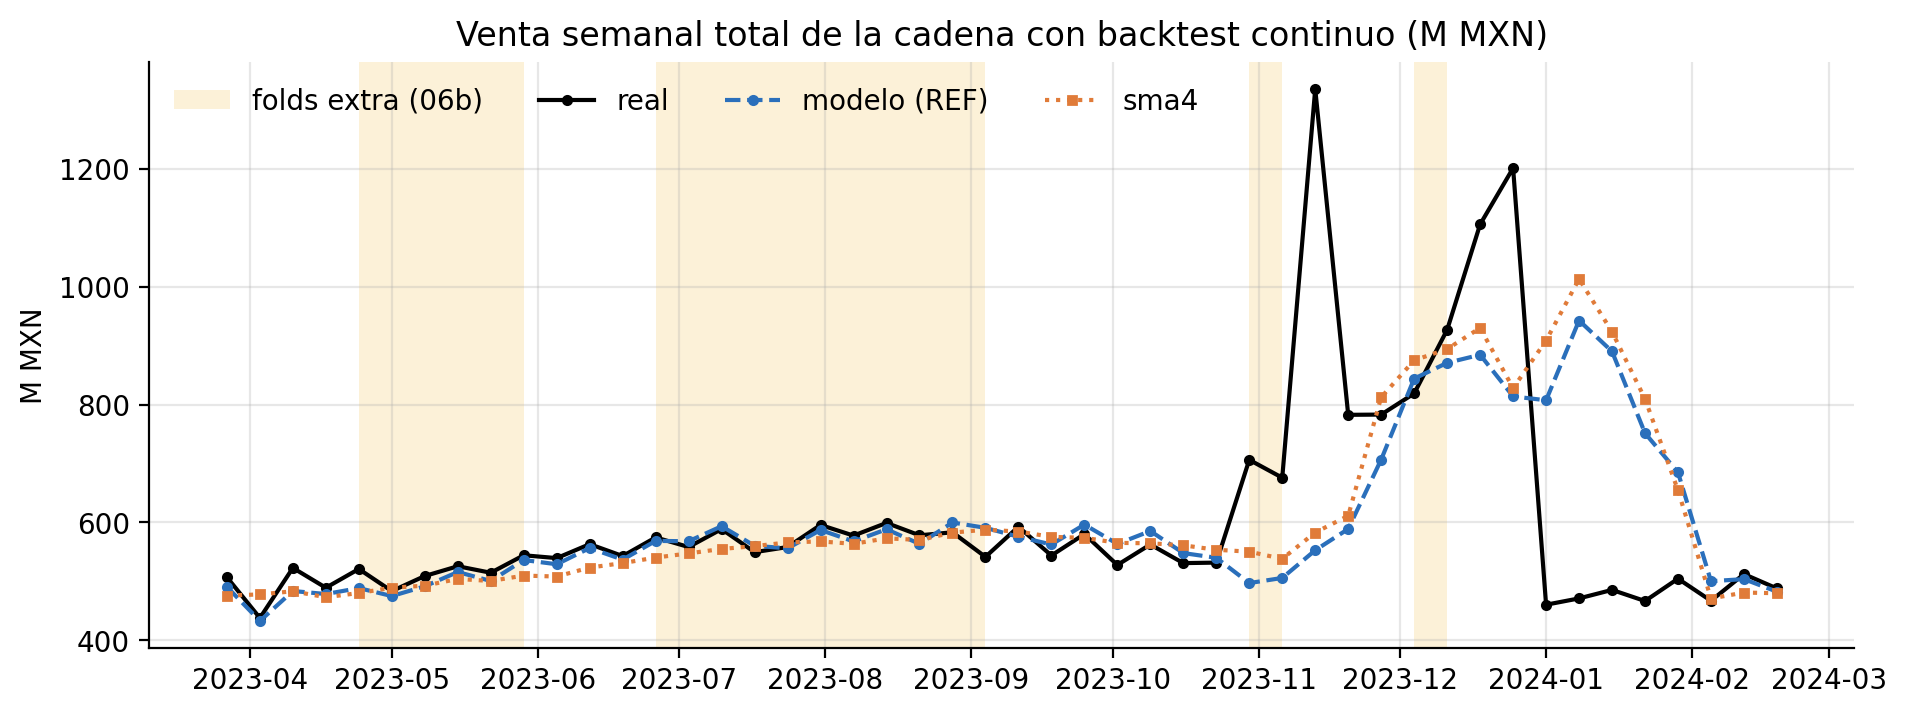

In [4]:
def weekly(df, cs):
    """Totales de cadena por semana (M MXN), con las mismas filas elegibles para real y pronóstico."""
    return add_week(df).groupby('semana')[['y'] + cs].sum().div(1e6)

W0 = weekly(ref, ['pred_ref', 'base_sma4'])
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, f in enumerate(EXTRA): ax.axvspan(pd.Timestamp(f.start), pd.Timestamp(f.end) + pd.Timedelta(days=1), color='#f2c14e', alpha=.22, lw=0, label='folds extra (06b)' if i == 0 else None)
ax.plot(W0.index, W0.y, 'k-o', ms=3, label='real'); ax.plot(W0.index, W0.pred_ref, color='#2a6fbb', marker='o', ms=3, ls='--', label='modelo (REF)'); ax.plot(W0.index, W0.base_sma4, color='#e07b39', marker='s', ms=3, ls=':', label='sma4')
ax.set(title='Venta semanal total de la cadena con backtest continuo (M MXN)', ylabel='M MXN'); ax.legend(frameon=False, ncol=4, loc='upper left'); plt.show()

### 1.1 Qué cambia al cubrir todo el año (solo REF, sin variantes)

In [ ]:
MR = T.fold_metrics(ref, {'REF': 'pred_ref', 'sma4': 'base_sma4', 'snaive': 'base_snaive', 'ma28': 'base_ma28'})
ex = MR[MR.fold.isin([f.name for f in EXTRA])].pivot_table(index='fold', columns='modelo', values='wape').mul(100)[['REF', 'sma4', 'snaive', 'ma28']].reindex([f.name for f in ALL if f.name not in OFFICIAL])
print('WAPE % serie x semana en los folds extra (solo se reportan):'); display(ex.round(1))
r = ref[ref.kind == 'regular']; off_reg = r.fold.isin(OFFICIAL)
rows = {'regulares oficiales': compare(r[off_reg], 'pred_ref', 'base_sma4'), 'regulares extra': compare(r[~off_reg], 'pred_ref', 'base_sma4'), 'todos los regulares': compare(r, 'pred_ref', 'base_sma4')}
S = pd.DataFrame(rows).T; S.columns = ['WAPE REF', 'WAPE sma4', 'Δ pts', 'IC95 inf', 'IC95 sup', 'p (bootstrap)', 'semanas', 'semanas REF mejor', 'p Wilcoxon']; S

WAPE % serie × semana en los folds extra (solo se reportan):


modelo,REF,sma4,snaive,ma28
fold,,,,
abr_may_2023,7.50,7.60,9.00,7.90
jun_jul_2023,7.00,7.60,8.60,7.80
jul_ago_2023,6.70,7.30,9.40,7.20
ago_sep_2023,7.10,6.70,8.60,6.70
pre_buen_fin_2023,29.60,22.10,24.90,21.90
pre_navidad_2023,8.80,9.20,9.30,8.00


,WAPE REF,WAPE sma4,Δ pts,IC95 inf,IC95 sup,p (bootstrap),semanas,semanas REF mejor,p Wilcoxon
regulares oficiales,7.59,8.19,-0.60,-1.11,-0.15,0.01,18.00,11.00,0.04
regulares extra,7.06,7.38,-0.32,-0.61,-0.03,0.03,15.00,9.00,0.19
todos los regulares,7.34,7.81,-0.47,-0.78,-0.19,0.00,33.00,20.00,0.01


**Lectura.**
- Cubrir el año refuerza la conclusión del 06 sin cambiarla. Con 33 semanas regulares (18 oficiales + 15 extra), REF obtiene 7.34 % contra 7.81 % de `sma4` (−0.47 pts, IC95 [−0.78, −0.19], Wilcoxon p = 0.01, gana 20 de 33 semanas). Con las 18 originales el IC era [−1.11, −0.15] y p = 0.04.
- La mejora en los folds extra regulares es menor (−0.32 pts, IC95 [−0.61, −0.03]) y no es pareja: REF gana en abr–may, jun–jul y jul–ago (6.7 % vs 7.3 %), y pierde contra `sma4` en `ago_sep_2023` (7.1 % vs 6.7 %; son solo 2 semanas, no concluyente).
- Las dos semanas que faltaban junto a eventos se comportan distinto. `pre_navidad_2023` es normal (8.8 %). `pre_buen_fin_2023` (30-oct a 5-nov) tiene WAPE 29.6 % y sesgo −29.6 %: la venta ya subió 33 % sobre la semana previa (532 → 706 M) y REF queda peor que `sma4` (22.1 %). En el backtest oficial esa semana no aparecía.

## 2. Defecto que se quiere corregir
Del 06: en `post_navidad_2024` el modelo sobrepronostica +57 % (el mejor baseline es `snaive`, con 37.8 %). La causa es mecánica: los rezagos de 14–35 días y las ventanas de 28 días todavía contienen la rampa de diciembre, y el modelo, que nunca vio un fin de temporada alta en entrenamiento, los proyecta hacia adelante. La venta real vuelve de golpe al nivel base el 1 de enero. No hay forma de que un modelo aprenda ese reinicio con una sola temporada alta en los datos, por lo que se impone con una regla de calendario.

## 3. Idea 1: reinicio de régimen
Se usan las ventanas de la Fase 2 (hipótesis tomadas de 2023): **Buen Fin −21 a +20 días** alrededor de su primer día y **Navidad −17 a +14 días** alrededor del 25 de diciembre. Para una fecha *fuera* de ventana cuyos 4 rezagos base (14, 21, 28 y 35 días) tocan una ventana, se reemplaza el promedio `sma4` por el promedio de los **4 rezagos más recientes que caen fuera de toda ventana** (hasta 16 semanas atrás, mínimo 2). El pronóstico del modelo se multiplica por `limpio / sma4`. Dentro de las ventanas no se corrige, porque ahí el nivel alto de los rezagos sí es información (la rampa es real). Fuera de ventana y sin contaminación el factor es exactamente 1, así que los periodos regulares no cambian por construcción.

In [6]:
BF_WIN, XM_WIN = (-21, 20), (-17, 14)
bf0 = F.loc[F.is_buen_fin == 1, 'date'].min()
anchors = [(bf0, BF_WIN)] + [(pd.Timestamp(f'{y}-12-25'), XM_WIN) for y in (2022, 2023)]
days = pd.DatetimeIndex(sorted(F.date.unique())); in_win = pd.Series(False, index=days)
for a, (lo, hi) in anchors: in_win |= (days >= a + pd.Timedelta(days=lo)) & (days <= a + pd.Timedelta(days=hi))
runs = (in_win != in_win.shift()).cumsum()
print('Primer día de Buen Fin:', bf0.date(), '| ventanas de evento (unión):')
for _, g in in_win[in_win].groupby(runs[in_win]): print('  ', g.index.min().date(), '→', g.index.max().date())

def reset_factor(F, in_win, base_lag=14, n_refs=16, k=4, min_ok=2):
    lags = [base_lag + 7 * j for j in range(n_refs)]
    vals = np.column_stack([F.groupby(['store_id', 'category'], sort=False)['y'].shift(L).values for L in lags])
    flag = np.column_stack([in_win.reindex(pd.DatetimeIndex(F['date'] - pd.Timedelta(days=L))).fillna(False).values for L in lags]).astype(bool)
    ok = ~np.isnan(vals) & ~flag
    sel = ok & (np.cumsum(ok, axis=1) <= k); n = sel.sum(1)
    clean = np.where(n >= min_ok, np.where(sel, vals, 0.0).sum(1) / np.maximum(n, 1), np.nan)
    contam = flag[:, :4].any(1) & ~F['date'].map(in_win).fillna(False).values.astype(bool)     # fuera de ventana, rezagos base dentro
    fac = np.where(contam & ~np.isnan(clean) & F['base_sma4'].notna().values, clean / F['base_sma4'].values, 1.0)
    return pd.DataFrame({'clean_sma4': clean, 'contaminado': contam, 'reset_factor': fac}, index=F.index)

RF = reset_factor(F, in_win); F1 = F.join(RF)
fx = F1[F1.reset_factor != 1]
print('\nFechas con corrección:', fx.date.min().date(), '→', fx.date.max().date(), '| filas:', len(fx), 'de', len(F1))
print('Fechas contaminadas sin corrección posible (clean_sma4 NaN):', int((F1.contaminado & F1.clean_sma4.isna()).sum()))
print('Factor medio por semana (clean_sma4 / sma4):'); fx.assign(semana=lambda d: d.date.dt.to_period('W-SUN').dt.start_time).groupby('semana').reset_factor.agg(['mean', 'min', 'max', 'size']).round(3)

Primer día de Buen Fin: 2023-11-17 | ventanas de evento (unión):
   2023-01-01 → 2023-01-08
   2023-10-27 → 2024-01-08



Fechas con corrección: 2023-01-30 → 2024-02-12 | filas: 23520 de 204000
Fechas contaminadas sin corrección posible (clean_sma4 NaN): 7200
Factor medio por semana (clean_sma4 / sma4):


,mean,min,max,size
semana,,,,
2023-01-30,1.03,0.70,1.58,3360
2023-02-06,1.00,0.78,1.22,3360
2024-01-08,0.59,0.25,1.20,2880
2024-01-15,0.64,0.25,1.45,3360
2024-01-22,0.71,0.25,1.27,3360
2024-01-29,0.82,0.41,1.34,3360
2024-02-05,1.06,0.78,1.54,3360
2024-02-12,1.03,0.86,1.25,480


## 4. Idea 2: estructura multiplicativa
REF predice `log(y)` con features en logaritmos: para reproducir un nivel que nunca vio, un árbol necesita hojas con ese nivel, y no extrapola más allá de lo visto en entrenamiento. Aquí el modelo aprende el **multiplicador sobre el baseline**, `log(y) − log(base_sma4)`, con las mismas 30 features e hiperparámetros, y el pronóstico es `base_sma4 x exp(f)`. Como `base_sma4` ya es el promedio del *mismo día de la semana*, el efecto día-de-semana queda fuera del objetivo y el modelo se concentra en la parte de calendario y evento.

In [7]:
def run_backtest_ratio(F, cfg, params, cols, folds):
    out = []
    for f in folds:
        tr = F[(F['date'] <= f.train_cutoff(cfg.horizon)) & F['eligible']]
        te = F[f.test_mask(F['date']) & F['eligible']][KEY].copy()
        m = lgb.LGBMRegressor(**params).fit(tr[cols], np.log(tr['y']) - np.log(tr['base_sma4']))
        te['pred_v2'] = F.loc[te.index, 'base_sma4'].values * np.exp(m.predict(F.loc[te.index, cols]))
        out.append(te)
    return pd.concat(out, ignore_index=True)

r2 = run_backtest_ratio(F, cfg, P0, cols, ALL)
P = ref.merge(r2, on=KEY, how='left').merge(F1[KEY + ['reset_factor']], on=KEY, how='left')
P['pred_v1'] = P.pred_ref * P.reset_factor; P['pred_v12'] = P.pred_v2 * P.reset_factor
assert P[['pred_ref', 'pred_v1', 'pred_v2', 'pred_v12']].notna().all().all() and len(P) == len(ref)
print('filas:', len(P), '| V1 difiere de REF en los folds regulares solo en:', sorted(P[(P.kind == 'regular') & ((P.pred_v1 - P.pred_ref).abs() > 1e-9)].fold.unique()))

filas: 161262 | V1 difiere de REF en los folds regulares solo en: ['feb_2024']


## 5. Resultados

In [ ]:
V = {'REF': 'pred_ref', 'V1 reinicio': 'pred_v1', 'V2 multiplicativo': 'pred_v2', 'V1+V2': 'pred_v12', 'sma4': 'base_sma4'}
M = T.fold_metrics(P, V); Mt = T.fold_metrics(P, V, 'total x semana'); order = [f.name for f in ALL]
meta = cov[['tipo', 'origen']]
def tab(M, v):
    t = M.pivot_table(index='fold', columns='modelo', values=v).mul(100).reindex(order)[list(V)]
    return meta.join(t)
print('WAPE % serie x semana (la métrica del 06):'); display(tab(M, 'wape').round(1))
print('Sesgo % de cadena (Σ(pronóstico − real) / Σreal; positivo = sobrepronóstico):'); display(tab(M, 'bias').round(1))
print('WAPE % total de cadena x semana (error de nivel, sin el reparto entre series):'); display(tab(Mt, 'wape').round(1))

WAPE % serie × semana (la métrica del 06):


,tipo,origen,REF,V1 reinicio,V2 multiplicativo,V1+V2,sma4
fold,,,,,,,
semana_santa_2023,regular,oficial (06),7.60,7.60,6.90,6.90,8.70
abr_may_2023,regular,extra (06b),7.50,7.50,7.20,7.20,7.60
may_jun_2023,regular,oficial (06),7.00,7.00,7.00,7.00,8.10
jun_jul_2023,regular,extra (06b),7.00,7.00,6.90,6.90,7.60
jul_ago_2023,regular,extra (06b),6.70,6.70,6.70,6.70,7.30
ago_sep_2023,regular,extra (06b),7.10,7.10,7.00,7.00,6.70
sep_2023,regular,oficial (06),8.20,8.20,8.40,8.40,8.10
oct_2023,regular,oficial (06),7.80,7.80,7.80,7.80,8.00
pre_buen_fin_2023,evento,extra (06b),29.60,29.60,29.80,29.80,22.10


Sesgo % de cadena (Σ(pronóstico − real) / Σreal; positivo = sobrepronóstico):


,tipo,origen,REF,V1 reinicio,V2 multiplicativo,V1+V2,sma4
fold,,,,,,,
semana_santa_2023,regular,oficial (06),-3.60,-3.60,-1.90,-1.90,-2.40
abr_may_2023,regular,extra (06b),-3.20,-3.20,-3.00,-3.00,-3.40
may_jun_2023,regular,oficial (06),-1.40,-1.40,-1.60,-1.60,-5.40
jun_jul_2023,regular,extra (06b),0.90,0.90,1.10,1.10,-3.00
jul_ago_2023,regular,extra (06b),-1.30,-1.30,-1.20,-1.20,-2.60
ago_sep_2023,regular,extra (06b),0.20,0.20,0.10,0.10,-0.70
sep_2023,regular,oficial (06),3.00,3.00,2.50,2.50,2.80
oct_2023,regular,oficial (06),3.90,3.90,1.60,1.60,4.30
pre_buen_fin_2023,evento,extra (06b),-29.60,-29.60,-29.80,-29.80,-22.10


WAPE % total de cadena × semana (error de nivel, sin el reparto entre series):


,tipo,origen,REF,V1 reinicio,V2 multiplicativo,V1+V2,sma4
fold,,,,,,,
semana_santa_2023,regular,oficial (06),3.60,3.60,1.90,1.90,6.50
abr_may_2023,regular,extra (06b),3.20,3.20,3.00,3.00,3.90
may_jun_2023,regular,oficial (06),1.40,1.40,1.60,1.60,5.40
jun_jul_2023,regular,extra (06b),1.40,1.40,1.50,1.50,3.90
jul_ago_2023,regular,extra (06b),1.30,1.30,1.20,1.20,3.30
ago_sep_2023,regular,extra (06b),2.70,2.70,2.60,2.60,0.70
sep_2023,regular,oficial (06),4.50,4.50,5.00,5.00,4.10
oct_2023,regular,oficial (06),3.90,3.90,3.80,3.80,4.30
pre_buen_fin_2023,evento,extra (06b),29.60,29.60,29.80,29.80,22.10


**Lectura.**
- **V1 solo cambia donde debía cambiar.** Es idéntico a REF en todos los folds regulares salvo la primera semana de `feb_2024` (el 12-feb tiene un rezago de 35 días que cae el 8-ene): 7.1 → 7.0 %.
- **Post-Navidad:** V1 baja el WAPE de 57.9 % a 14.8 % y el sesgo de cadena de +57.4 % a +13.6 %. El mejor baseline del 06 (`snaive`) tenía 37.8 %.
- **V2 solo** mueve poco: Navidad 28.5 → 27.0 %, Buen Fin 34.5 → 34.0 %, `semana_santa_2023` 7.6 → 6.9 %. Empeora `pre_navidad_2023` (8.8 → 10.0 %, sesgo +8 %) y no corrige post-Navidad (59.8 %).
- **El error en eventos es de nivel de cadena.** En Buen Fin y Navidad el WAPE de total x semana (34.2 % y 27.4 %) es casi el mismo que el de serie × semana (34.5 % y 28.5 %): el problema no es el reparto entre tiendas y categorías, sino cuánto vende la cadena completa.

### 5.1 Criterios de sustitución

In [9]:
cand = ['V1 reinicio', 'V2 multiplicativo', 'V1+V2']; reg_folds = [f.name for f in ALL if f.kind == 'regular']
w = lambda m, fs: M[(M.modelo == m) & M.fold.isin(fs)].wape.mean() * 100
rows = []
for m in cand:
    rows.append({'variante': m, 'C1 Δ WAPE regulares (pts)': w(m, reg_folds) - w('REF', reg_folds),
                 'C2 sesgo post_navidad (%)': M[(M.modelo == m) & (M.fold == 'post_navidad_2024')].bias.iloc[0] * 100,
                 'C3 Δ WAPE Buen Fin (pts)': w(m, ['buen_fin_2023']) - w('REF', ['buen_fin_2023']),
                 'C3 Δ WAPE Navidad (pts)': w(m, ['navidad_2023']) - w('REF', ['navidad_2023'])})
C = pd.DataFrame(rows).set_index('variante')
C['C1 ok'] = C['C1 Δ WAPE regulares (pts)'] <= 0.2; C['C2 ok'] = C['C2 sesgo post_navidad (%)'].abs() <= 15
C['C3 ok'] = (C[['C3 Δ WAPE Buen Fin (pts)', 'C3 Δ WAPE Navidad (pts)']] <= 1).all(axis=1); C['cumple las 3'] = C[['C1 ok', 'C2 ok', 'C3 ok']].all(axis=1)
print('REF: WAPE medio regulares %.2f %% | sesgo post_navidad %.1f %%' % (w('REF', reg_folds), M[(M.modelo == 'REF') & (M.fold == 'post_navidad_2024')].bias.iloc[0] * 100)); C

REF: WAPE medio regulares 7.31 % | sesgo post_navidad 57.4 %


,C1 Δ WAPE regulares (pts),C2 sesgo post_navidad (%),C3 Δ WAPE Buen Fin (pts),C3 Δ WAPE Navidad (pts),C1 ok,C2 ok,C3 ok,cumple las 3
variante,,,,,,,,
V1 reinicio,-0.00,13.61,0.00,0.00,True,True,True,True
V2 multiplicativo,-0.10,59.15,-0.52,-1.51,True,False,True,False
V1+V2,-0.10,13.18,-0.52,-1.51,True,True,True,True


In [10]:
ext_reg = [f.name for f in EXTRA if f.kind == 'regular']
R = pd.DataFrame({m: {'desarrollo (pts vs REF)': w(m, T.DEV_FOLDS) - w('REF', T.DEV_FOLDS), 'confirmación (pts vs REF)': w(m, T.CONFIRM_FOLDS) - w('REF', T.CONFIRM_FOLDS),
                      'extra regulares (pts vs REF)': w(m, ext_reg) - w('REF', ext_reg)} for m in cand}).T
print('Regla del 06 para adoptar un cambio: mejora >= %.1f pts en desarrollo (diferencia negativa = mejor).' % T.MIN_GAIN); display(R)
tst = P[KEY].merge(F1[KEY + ['contaminado', 'clean_sma4']], on=KEY)
print('Filas de prueba con rezagos contaminados y sin ancla limpio disponible:', int((tst.contaminado & tst.clean_sma4.isna()).sum()))

Regla del 06 para adoptar un cambio: mejora >= 0.2 pts en desarrollo (diferencia negativa = mejor).


,desarrollo (pts vs REF),confirmación (pts vs REF),extra regulares (pts vs REF)
V1 reinicio,0.00,-0.01,0.00
V2 multiplicativo,-0.17,-0.04,-0.08
V1+V2,-0.17,-0.05,-0.08


Filas de prueba con rezagos contaminados y sin ancla limpio disponible: 0


**Lectura.**
- **V1 cumple las tres condiciones**, pero C2 por poco: sesgo +13.6 % contra un máximo de 15 %. C1 y C3 se cumplen por construcción, porque V1 no cambia nada fuera de enero–febrero de 2024.
- **V2 solo no cumple C2** y su mejora en regulares queda bajo el umbral del 06: −0.17 pts en desarrollo contra los 0.2 requeridos (−0.04 en confirmación, −0.08 en los extra regulares). Con la regla ya fijada, no se adopta.
- **V1+V2** cumple las tres, pero lo que añade sobre V1 es mínimo (post-Navidad 14.8 → 14.5 %; Navidad −1.5 pts) y viene de V2, que por sí solo no pasa la regla de adopción.
- C2 y C3 se miden sobre un único evento, y el defecto de C2 se diagnosticó mirando ese mismo fold (sección 0). Cumplirlos prueba que se corrige un defecto mecánico, no que se generalice a 2024.

### 5.2 Totales de cadena por semana en la temporada alta

In [11]:
cs = ['pred_ref', 'pred_v1', 'pred_v2', 'pred_v12']; Wz = weekly(P, cs).loc['2023-10-30':]
err = Wz[cs].div(Wz.y, axis=0).sub(1).mul(100).add_prefix('err % ')
pd.concat([Wz.round(0), err.round(0)], axis=1).rename(columns={'y': 'real'})

,real,pred_ref,pred_v1,pred_v2,pred_v12,err % pred_ref,err % pred_v1,err % pred_v2,err % pred_v12
semana,,,,,,,,,
2023-10-30,706.00,497.00,497.00,496.00,496.00,-30.00,-30.00,-30.00,-30.00
2023-11-06,676.00,506.00,506.00,504.00,504.00,-25.00,-25.00,-25.00,-25.00
2023-11-13,"1,336.00",553.00,553.00,556.00,556.00,-59.00,-59.00,-58.00,-58.00
2023-11-20,783.00,589.00,589.00,591.00,591.00,-25.00,-25.00,-24.00,-24.00
2023-11-27,783.00,707.00,707.00,737.00,737.00,-10.00,-10.00,-6.00,-6.00
2023-12-04,819.00,844.00,844.00,885.00,885.00,3.00,3.00,8.00,8.00
2023-12-11,927.00,871.00,871.00,916.00,916.00,-6.00,-6.00,-1.00,-1.00
2023-12-18,"1,106.00",885.00,885.00,943.00,943.00,-20.00,-20.00,-15.00,-15.00
2023-12-25,"1,202.00",814.00,814.00,825.00,825.00,-32.00,-32.00,-31.00,-31.00


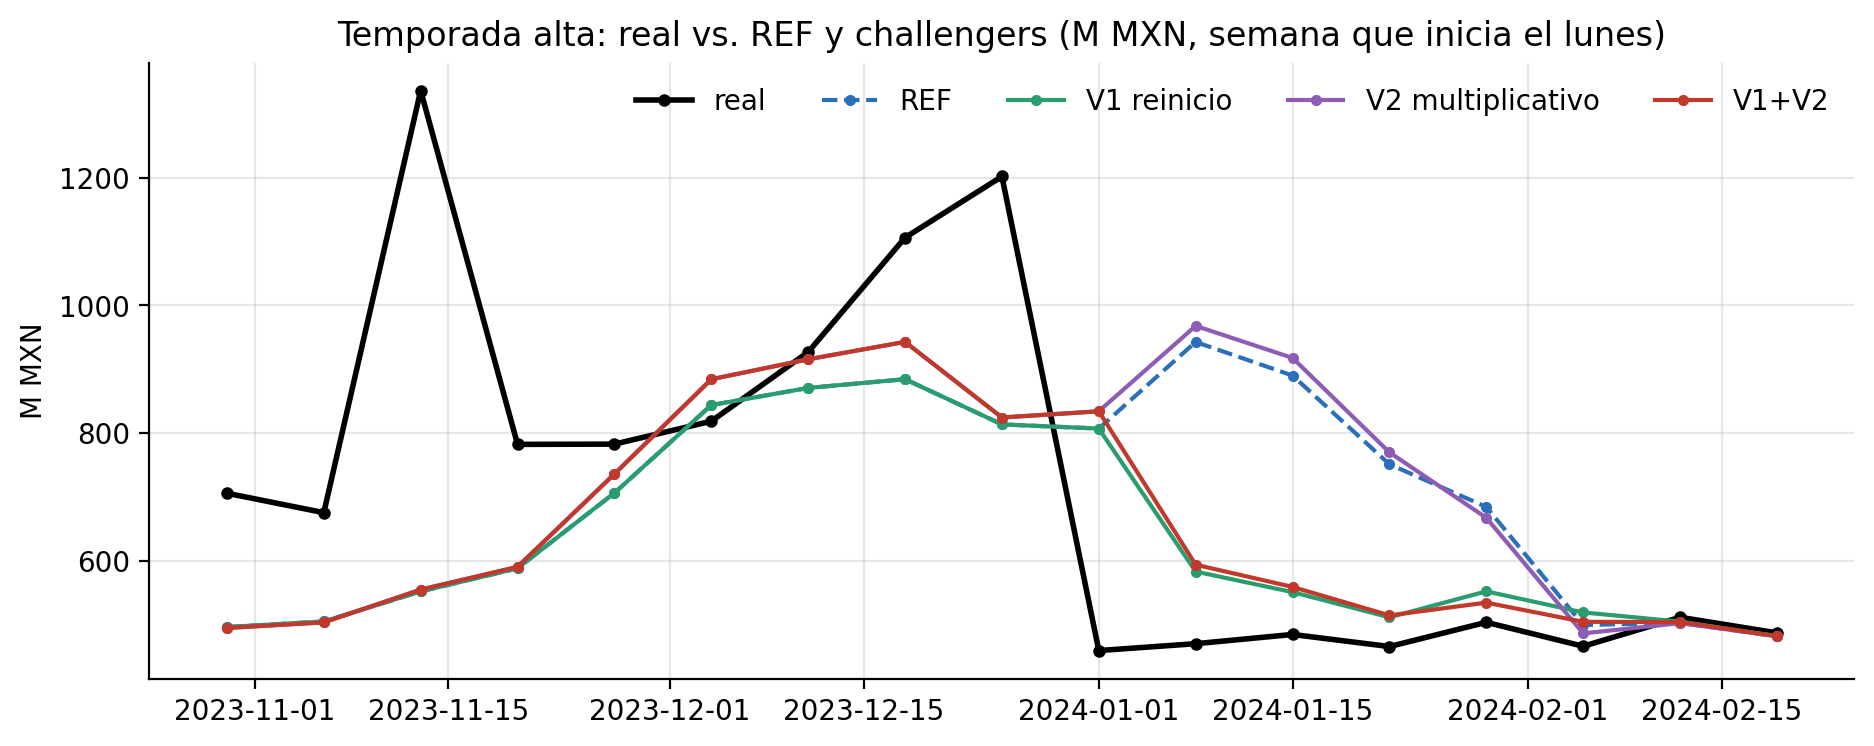

In [12]:
col = {'pred_ref': '#2a6fbb', 'pred_v1': '#2a9d6f', 'pred_v2': '#8e5bb5', 'pred_v12': '#c0392b'}; lab = {'pred_ref': 'REF', 'pred_v1': 'V1 reinicio', 'pred_v2': 'V2 multiplicativo', 'pred_v12': 'V1+V2'}
fig, ax = plt.subplots(figsize=(11, 4)); ax.plot(Wz.index, Wz.y, 'k-o', ms=3.5, lw=2, label='real')
for c_ in cs: ax.plot(Wz.index, Wz[c_], color=col[c_], marker='o', ms=3, ls='--' if c_ == 'pred_ref' else '-', label=lab[c_])
ax.set(title='Temporada alta: real vs. REF y challengers (M MXN, semana que inicia el lunes)', ylabel='M MXN'); ax.legend(frameon=False, ncol=5, loc='upper right'); plt.show()

**Lectura.**
- Con V1 las semanas de enero pasan de +100 / +83 / +61 / +36 % a +24 / +14 / +10 / +10 % (8-ene a 29-ene).
- Queda sobrepronóstico de 10–24 %, por dos razones. (a) V1 reescala el pronóstico por `sma4 limpio / sma4`, pero otras features (`roll_mean_7`, `roll_mean_28`, `lag_14d`) siguen contaminadas. (b) El ancla limpia viene de octubre, cuyo nivel semanal (≈ 530–560 M) es más alto que el de enero (460–505 M): es estacionalidad anual que con 14 meses de datos no se puede estimar.
- La semana del 1-ene sigue en +75 % (+81 % con V2). Cae dentro de la ventana de Navidad (que termina el 8-ene), donde V1 no corrige, pero la caída real ocurre el 1-ene. Cerrarlo exigiría terminar el régimen el 31-dic en lugar de +14 días, algo que solo se puede validar con una ocurrencia.
- **Rampa y Buen Fin no mejoran con ninguna variante:** −59 % en la semana del Buen Fin y −31 % / −32 % en la del 25-dic. V2 recorta un poco la rampa (18-dic: −20 % → −15 %), pero ninguna alcanza el pico. Coincide con la Fase 2: esa magnitud no se puede aprender con una sola ocurrencia.
- En la semana del 5-feb V1 sobrecorrige un poco (+11 % vs +7 % de REF), porque el ancla ya mezcla octubre con días recientes.

### 5.3 ¿Cambia algo en periodos regulares? (significancia sobre todas las semanas regulares)

In [13]:
rg = P[P.kind == 'regular']
S2 = pd.DataFrame({m: compare(rg, c_, 'pred_ref') for m, c_ in [('V1 reinicio', 'pred_v1'), ('V2 multiplicativo', 'pred_v2'), ('V1+V2', 'pred_v12')]}).T
S2.columns = ['WAPE variante', 'WAPE REF', 'Δ pts', 'IC95 inf', 'IC95 sup', 'p (bootstrap)', 'semanas', 'semanas variante mejor', 'p Wilcoxon']; S2

,WAPE variante,WAPE REF,Δ pts,IC95 inf,IC95 sup,p (bootstrap),semanas,semanas variante mejor,p Wilcoxon
V1 reinicio,7.34,7.34,-0.00,-0.00,0.00,0.75,33.00,1.00,0.32
V2 multiplicativo,7.24,7.34,-0.10,-0.25,0.03,0.14,33.00,19.00,0.23
V1+V2,7.24,7.34,-0.10,-0.25,0.03,0.13,33.00,19.00,0.20


**Lectura.** V1 es idéntico en regulares (Δ 0.00 pts). V2 mejora −0.10 pts (IC95 [−0.25, +0.03], Wilcoxon p = 0.23, mejor en 19 de 33 semanas): no se distingue de cero.

## 6. Ampliación: revisión de ventanas y fin de régimen el 31-dic
**Protocolo de esta ampliación.** Se define *después* de ver los resultados de V1 (secciones 3–5) y *antes* de ejecutar lo que sigue. Hay que decirlo con claridad: el fold post-Navidad ya se usó para diagnosticar el defecto, y la idea del 31-dic nace de ver que la semana del 1-ene seguía en +75 %. Los resultados de esta sección son por tanto **exploratorios** y no cuentan como validación.

**6.1 Sensibilidad a las ventanas (de V1).** Se varía una ventana a la vez (Buen Fin: antes 14/21/28 y después 14/20/28 días; Navidad: antes 10/17/24 y después 7/14/21), más una configuración «todas cortas» y otra «todas largas». Criterio fijado: las ventanas se consideran **robustas** si ninguna configuración empeora los folds de rampa (`pre_navidad_2023`, `navidad_2023`) en más de 2 pts de WAPE frente a REF. Si alguna lo hace, se documenta qué parámetro es crítico y se conserva la ventana de la Fase 2.

**6.2 V1b, fin de régimen el 31-dic.** Se separan dos ventanas de Navidad: la de **referencia** (qué días contaminan los rezagos) sigue hasta +14 días (8-ene), y la de **destino** (qué fechas se corrigen) termina en +6 días (31-dic), de modo que desde el 1-ene el pronóstico ya se reinicia. Criterios para preferir V1b sobre V1:
- C1 intacto: regulares no más de 0.2 pts peores que REF.
- El sesgo de post-Navidad no empeora frente a V1 (tolerancia de +0.5 pts).
- `pre_navidad_2023` y `buen_fin_2023` quedan iguales (están dentro de la ventana), y `navidad_2023` no empeora más de 1 pt frente a V1.
- En la tabla de fin de régimen (+6, +12 y +14 días) el resultado no puede depender de forma delicada del valor elegido.

In [14]:
VALS = np.column_stack([F.groupby(['store_id', 'category'], sort=False)['y'].shift(14 + 7 * j).values for j in range(16)])
def make_win(bf=(-21, 20), xm=(-17, 14)):
    w = pd.Series(False, index=days)
    for a, (lo, hi) in [(bf0, bf)] + [(pd.Timestamp(f'{y}-12-25'), xm) for y in (2022, 2023)]:
        w |= (days >= a + pd.Timedelta(days=lo)) & (days <= a + pd.Timedelta(days=hi))
    return w

def factor2(win_ref, win_tgt, k=4, min_ok=2):
    """Como reset_factor, pero con ventana de referencia (qué rezagos contaminan) y de destino (qué fechas se corrigen)."""
    flag = np.column_stack([win_ref.reindex(pd.DatetimeIndex(F['date'] - pd.Timedelta(days=14 + 7 * j))).fillna(False).values for j in range(16)]).astype(bool)
    ok = ~np.isnan(VALS) & ~flag; sel = ok & (np.cumsum(ok, axis=1) <= k); n = sel.sum(1)
    clean = np.where(n >= min_ok, np.where(sel, VALS, 0.0).sum(1) / np.maximum(n, 1), np.nan)
    contam = flag[:, :4].any(1) & ~F['date'].map(win_tgt).fillna(False).values.astype(bool)
    return np.where(contam & ~np.isnan(clean) & F['base_sma4'].notna().values, clean / F['base_sma4'].values, 1.0)

w0 = make_win(); assert np.allclose(factor2(w0, w0), F1.reset_factor.values), 'factor2 no reproduce reset_factor'
print('factor2 con las mismas ventanas reproduce reset_factor de la sección 3.')
fkeys = F[KEY].reset_index(drop=True)
def eval_fac(fac):
    f = P[KEY].merge(fkeys.assign(fac=fac), on=KEY, how='left')['fac'].values
    Q = P.assign(pred_x=P.pred_ref * f); m = T.fold_metrics(Q, {'x': 'pred_x'}).set_index('fold')
    g = lambda fold, c: m.loc[fold, c] * 100
    return {'post_nav WAPE': g('post_navidad_2024', 'wape'), 'post_nav sesgo': g('post_navidad_2024', 'bias'), 'navidad WAPE': g('navidad_2023', 'wape'),
            'pre_navidad WAPE': g('pre_navidad_2023', 'wape'), 'buen_fin WAPE': g('buen_fin_2023', 'wape'), 'pre_buen_fin WAPE': g('pre_buen_fin_2023', 'wape'),
            'Δ regulares (pts)': m[m.tipo == 'regular'].wape.mean() * 100 - w('REF', reg_folds)}

factor2 con las mismas ventanas reproduce reset_factor de la sección 3.


### 6.1 Sensibilidad a las ventanas

In [15]:
cfgs = {'Fase 2 (base)': dict(), 'Buen Fin antes 14': dict(bf=(-14, 20)), 'Buen Fin antes 28': dict(bf=(-28, 20)), 'Buen Fin después 14': dict(bf=(-21, 14)), 'Buen Fin después 28': dict(bf=(-21, 28)),
        'Navidad antes 10': dict(xm=(-10, 14)), 'Navidad antes 24': dict(xm=(-24, 14)), 'Navidad después 7': dict(xm=(-17, 7)), 'Navidad después 21': dict(xm=(-17, 21)),
        'todas cortas': dict(bf=(-14, 14), xm=(-10, 7)), 'todas largas': dict(bf=(-28, 28), xm=(-24, 21))}
rows = {'REF (sin reinicio)': eval_fac(np.ones(len(F)))}
for k, kw in cfgs.items():
    wi = make_win(**kw); rows[k] = eval_fac(factor2(wi, wi))
SW = pd.DataFrame(rows).T
ref_ramp = SW.loc['REF (sin reinicio)', ['pre_navidad WAPE', 'navidad WAPE']]
SW['rampa peor > 2 pts'] = ((SW[['pre_navidad WAPE', 'navidad WAPE']] - ref_ramp) > 2).any(axis=1)
SW.round(1)

,post_nav WAPE,post_nav sesgo,navidad WAPE,pre_navidad WAPE,buen_fin WAPE,pre_buen_fin WAPE,Δ regulares (pts),rampa peor > 2 pts
REF (sin reinicio),57.90,57.40,28.50,8.80,34.50,29.60,0.00,False
Fase 2 (base),14.80,13.60,28.50,8.80,34.50,29.60,-0.00,False
Buen Fin antes 14,19.10,18.50,28.50,8.80,34.50,29.60,-0.00,False
Buen Fin antes 28,15.60,14.60,28.50,8.80,34.50,29.60,-0.00,False
Buen Fin después 14,25.30,25.00,28.50,12.10,37.20,29.60,-0.00,True
Buen Fin después 28,14.80,13.60,28.50,8.80,34.50,29.60,-0.00,False
Navidad antes 10,29.50,29.30,30.40,20.10,34.50,29.60,-0.00,True
Navidad antes 24,14.80,13.60,28.50,8.80,34.50,29.60,-0.00,False
Navidad después 7,11.20,8.90,20.90,8.80,34.50,29.60,0.00,False
Navidad después 21,33.90,33.40,28.50,8.80,34.50,29.60,-0.00,False


**Lectura.** Con el criterio fijado, las ventanas **no son robustas**: tres configuraciones empeoran la rampa más de 2 pts frente a REF (`Buen Fin después 14`, `Navidad antes 10` y `todas cortas`). Se conserva la ventana de la Fase 2 y se documentan los parámetros críticos:
- **Las ventanas no pueden dejar huecos dentro de la temporada alta.** `Buen Fin después 14` termina el 1-dic y la de Navidad empieza el 8-dic: las fechas del 2 al 7 de diciembre quedan fuera de evento con rezagos contaminados, el factor las baja hacia el nivel de octubre y `pre_navidad_2023` pasa de 8.8 % a 12.1 % (Buen Fin de 34.5 % a 37.2 %). `Navidad antes 10` y `todas cortas` fallan por lo mismo (`pre_navidad_2023` en 20.1 % y 31.8 %).
- **La ventana de Buen Fin debe empezar antes de la pre-rampa.** Con 14 días en lugar de 21 el sesgo post-Navidad sube de +13.6 % a +18.5 %, probablemente porque el ancla limpio ya incluye días elevados (27-oct a 2-nov). Con 28 días casi no cambia (+14.6 %).
- **El fin de la ventana de Navidad es el parámetro que más mueve el resultado post-evento:** el sesgo es +8.9 % con 7 días, +13.6 % con 14 y +33.4 % con 21. `todas largas` falla por este parámetro. Eso motiva la sección 6.2.
- Alargar el final de la ventana de Buen Fin (28 días) o el inicio de la de Navidad (24 días) no cambia nada, porque ambas ya se traslapan.

### 6.2 V1b: fin de régimen el 31-dic

In [16]:
wr = make_win()
rows = {'V1 (destino hasta +14 = 8-ene)': eval_fac(factor2(wr, make_win(xm=(-17, 14)))),
        'destino hasta +12 (6-ene)': eval_fac(factor2(wr, make_win(xm=(-17, 12)))),
        'V1b destino hasta +6 (31-dic)': eval_fac(factor2(wr, make_win(xm=(-17, 6))))}
EB = pd.DataFrame(rows).T; display(EB.round(1))
fac_b = factor2(wr, make_win(xm=(-17, 6)))
P['pred_v1b'] = P.pred_ref * P[KEY].merge(fkeys.assign(fac=fac_b), on=KEY, how='left')['fac'].values
cs2 = ['pred_ref', 'pred_v1', 'pred_v1b']; Wb = weekly(P, cs2).loc['2023-12-18':'2024-02-12']
err2 = Wb[cs2].div(Wb.y, axis=0).sub(1).mul(100).add_prefix('err % ')
pd.concat([Wb.round(0), err2.round(0)], axis=1).rename(columns={'y': 'real'})

,post_nav WAPE,post_nav sesgo,navidad WAPE,pre_navidad WAPE,buen_fin WAPE,pre_buen_fin WAPE,Δ regulares (pts)
V1 (destino hasta +14 = 8-ene),14.80,13.60,28.50,8.80,34.50,29.60,-0.00
destino hasta +12 (6-ene),12.80,11.30,26.20,8.80,34.50,29.60,-0.00
V1b destino hasta +6 (31-dic),12.80,11.30,20.70,8.80,34.50,29.60,-0.00


,real,pred_ref,pred_v1,pred_v1b,err % pred_ref,err % pred_v1,err % pred_v1b
semana,,,,,,,
2023-12-18,"1,106.00",885.00,885.00,885.00,-20.00,-20.00,-20.00
2023-12-25,"1,202.00",814.00,814.00,814.00,-32.00,-32.00,-32.00
2024-01-01,460.00,808.00,808.00,494.00,75.00,75.00,7.00
2024-01-08,471.00,943.00,584.00,529.00,100.00,24.00,12.00
2024-01-15,486.00,890.00,552.00,552.00,83.00,14.00,14.00
2024-01-22,467.00,752.00,512.00,512.00,61.00,10.00,10.00
2024-01-29,505.00,685.00,553.00,553.00,36.00,10.00,10.00
2024-02-05,467.00,500.00,520.00,520.00,7.00,11.00,11.00
2024-02-12,512.00,504.00,506.00,506.00,-2.00,-1.00,-1.00


In [ ]:
V2d = {'REF': 'pred_ref', 'V1 reinicio': 'pred_v1', 'V1b (31-dic)': 'pred_v1b'}; Mb = T.fold_metrics(P, V2d)
tb = Mb.pivot_table(index='fold', columns='modelo', values='wape').mul(100).reindex(order)[list(V2d)]
print('WAPE % serie x semana por fold:'); display(meta.join(tb).loc[['pre_buen_fin_2023', 'buen_fin_2023', 'pre_navidad_2023', 'navidad_2023', 'post_navidad_2024', 'feb_2024']].round(1))
wb = lambda m, fs: Mb[(Mb.modelo == m) & Mb.fold.isin(fs)].wape.mean() * 100
bb = lambda m: Mb[(Mb.modelo == m) & (Mb.fold == 'post_navidad_2024')].bias.iloc[0] * 100
print('Δ WAPE regulares vs REF (pts): V1 %.2f | V1b %.2f' % (wb('V1 reinicio', reg_folds) - wb('REF', reg_folds), wb('V1b (31-dic)', reg_folds) - wb('REF', reg_folds)))
print('Sesgo post_navidad (%%): V1 %.1f | V1b %.1f' % (bb('V1 reinicio'), bb('V1b (31-dic)')))

WAPE % serie × semana por fold:


,tipo,origen,REF,V1 reinicio,V1b (31-dic)
fold,,,,,
pre_buen_fin_2023,evento,extra (06b),29.60,29.60,29.60
buen_fin_2023,evento,oficial (06),34.50,34.50,34.50
pre_navidad_2023,evento,extra (06b),8.80,8.80,8.80
navidad_2023,evento,oficial (06),28.50,28.50,20.70
post_navidad_2024,post_evento,oficial (06),57.90,14.80,12.80
feb_2024,regular,oficial (06),7.10,7.00,7.00


Δ WAPE regulares vs REF (pts): V1 -0.00 | V1b -0.00
Sesgo post_navidad (%): V1 13.6 | V1b 11.3


**Lectura.**
- **V1b cumple los criterios fijados:** regulares intactos (−0.00 pts), sesgo post-Navidad +11.3 % (V1: +13.6 %), `pre_navidad_2023` y `buen_fin_2023` idénticos y `navidad_2023` de 28.5 % a 20.7 %. Post-Navidad queda en 12.8 % de WAPE.
- **La semana del 1-ene pasa de +75 % a +7 %** y la del 8-ene de +24 % a +12 %. Desde el 15-ene los números son los de V1 (+14, +10, +10 y +11 %): lo que queda es el ancla de octubre y las features contaminadas.
- **Sensibilidad al valor elegido.** Post-Navidad es igual con +6 y +12 días (12.8 %), pero `navidad_2023` va de 20.7 % (31-dic) a 26.2 % (6-ene) y 28.5 % (8-ene): cada día de retraso deja sin corregir más días de la primera semana de enero. Es mecánico y no se invierte, pero el beneficio depende de que el fin de régimen coincida con el día real del reinicio (1-ene), algo que solo se observa una vez.
- **Navidad sigue en 20.7 %** por la rampa (−20 % y −32 % en las semanas del 18 y 25-dic), que ninguna variante corrige.

## 7. Conclusiones

1. **Backtest continuo:** no es necesario para el modelo, pero conviene. Cubre 48 semanas seguidas (2023-03-27 → 2024-02-25), reproduce exactamente los 8 folds oficiales y casi duplica las semanas regulares disponibles (18 → 33), con una conclusión más firme sobre REF. Además muestra la semana pre-Buen Fin, que el esquema oficial no cubría. Se deja como informe complementario: incorporarlo a `FOLDS` cambiaría las métricas oficiales del 06, así que queda como decisión aparte.
2. **Idea 1 (reinicio de régimen):** corrige la histéresis sin cambiar los periodos regulares. V1 lleva post-Navidad de 57.9 % a 14.8 % de WAPE y de +57 % a +14 % de sesgo. V1b (fin de régimen el 31-dic) lo deja en 12.8 % y +11.3 %, y baja la semana del 1-ene de +75 % a +7 %.
3. **Ventanas:** no son robustas en el sentido fijado. Reglas que hay que respetar: sin huecos entre la ventana de Buen Fin y la de Navidad, inicio de la de Buen Fin al menos 21 días antes de su primer día, y fin del régimen alineado con el día real del reinicio. Se conservan las ventanas de la Fase 2.
4. **Idea 2 (multiplicativo):** no se justifica por sí sola (−0.17 pts en desarrollo contra los 0.2 requeridos; no toca post-Navidad ni los picos). No se adopta.
5. **Estado frente al 06:** el 06 sigue como versión oficial. V1b cumple C1–C3 con margen en C2 (+11.3 % contra un máximo de 15 %) y los criterios de 6.2, pero todo se midió con una sola ocurrencia y el fold de post-Navidad ya se había usado para diagnosticar. Se propone como capa de reinicio candidata, y la validación real será la segunda ocurrencia (diciembre de 2024 – enero de 2025).
6. **Pendiente:** ninguna variante mejora la magnitud del pico del Buen Fin (−59 %) ni la rampa navideña (−20 % y −32 %). Eso sigue dependiendo de escenarios e intervalos (p10/p90) y de una segunda ocurrencia.